# Train a Chest Pathology Adapter with MedImageInsight

Train a small classifier on frozen MedImageInsight embeddings for five chest X-ray categories: No Finding, Support Devices, Pleural Effusion, Cardiomegaly, and Atelectasis. The same workflow supports MedImageInsight and MedImageInsight Premium through the Healthcare AI Toolkit client factory.

Unlike [zero-shot classification](./zero-shot-classification.ipynb), this workflow uses labeled examples to train an adapter. It does not fine-tune the embedding model. Training runs locally on an available GPU or CPU; embedding generation uses your configured endpoint.

## Prerequisites

Follow the [repository setup instructions](../../README.md) to install the toolkit, download the sample data, and configure your `.env` file.

- Set `DATA_ROOT` to the directory containing `medimageinsight-classification`.
- Set `MI2_PREMIUM_ENDPOINT` or `MI2_MODEL_ENDPOINT` for your deployed model.

For a direct URL (including Foundry), also set the matching `MI2_PREMIUM_API_KEY` or `MI2_MODEL_API_KEY`. For an Azure ML endpoint ID or name, the client can retrieve the key using your Azure credentials if you have permission.

## Workflow

1. Generate image embeddings for the 100 sample DICOM images.
2. Join embeddings to the supplied labeled splits by image name.
3. Train the adapter and select a checkpoint using validation metrics.
4. Reload that checkpoint, evaluate it, and inspect example predictions.

This small tutorial dataset demonstrates the workflow; its results do not establish clinical performance.

## 1. Setup and Imports

In [ ]:
import os

import matplotlib.pyplot as plt
import pandas as pd
import SimpleITK as sitk
import torch
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from healthcareai_toolkit import settings
from model_library.embedding import AdapterModel
from model_library.utils import training, inference

sitk.ProcessObject_SetGlobalWarningDisplay(False)

### Select the Model Client

`get_medimage_client` is a helper for these example notebooks that creates a client from your configured endpoints. It selects Premium when configured, otherwise open-source, and raises an error if neither is configured.

Set `variant="premium"` or `variant="opensource"` to choose explicitly.

In [1]:
# Parameters
## Client Params
variant = None

In [2]:
from healthcareai_toolkit.clients import get_medimage_client

mi2_client = get_medimage_client("mi2", variant=variant)

print(mi2_client)

MedImageInsightPremiumClient(
    target='https://<account>.services.ai.azure.com/providers/microsoft/v2/embed',
    deployment_name='MedImageInsight-Premium',
    image_reader='sitk',
    resize_size=(480, 480)
)


### Input Data

The sample contains 100 DICOM images, with 20 images in each of the five categories. The toolkit reads and preprocesses each image to produce the input for the embedding endpoint.

The supplied `adaptor_tutorial_train_split.csv` and `adaptor_tutorial_test_split.csv` assign images to an 80-image training set and a 20-image test set. Each row contains an image name, a numeric `Label`, and its `Label Category`.

In [4]:
## Input Images and Text for Inference
data_root = settings.DATA_ROOT

if not os.path.exists(data_root):
    raise (
        Exception(
            f"Please download the files as described in this notebook into the data_root: {data_root}"
        )
    )

## Load image input folder for generating image embeddings
input_folder = os.path.join(data_root, "medimageinsight-classification", "images")
## Load csv folder labels and splits
csv_folder = os.path.join(data_root, "medimageinsight-classification", "csv")

## 2. Train an Adapter on Image Embeddings

Compute one 1,024-dimensional embedding per image, then use the supplied CSV files to assign those embeddings to the training and evaluation sets. Only the adapter weights are trained; the MedImageInsight endpoint is unchanged.

`AdapterModel` projects the input through two linear layers, applies a two-layer convolution block, and produces one logit for each of the five classes. The parameter cell below controls training. Its saved values are 5 epochs, a hidden dimension of 128, learning rate 0.001, batch size 48, AdamW weight decay 0.1, and seed 42.

The notebook currently uses `adaptor_tutorial_test_split.csv` for both validation and final evaluation. Checkpoint selection therefore uses the same examples as the reported test score. Keep this convenient tutorial split for exploration; use separate validation and test data for an independent evaluation.

### 2.1. Compute Image Embeddings

In [5]:
import glob

submitter = mi2_client.create_submitter(n_jobs=3)
image_files = list(glob.glob(input_folder + "/*.dcm"))
_, image_results = submitter.submit(image_list=image_files, total=len(image_files))

  0%|          | 0/100 [00:00<?, ?it/s]

100%|██████████| 100/100 [00:43<00:00,  2.28it/s]


### 2.2. Train Adapters

### Training Hyperparameters

Set the seed, model dimensions, and training hyperparameters below before creating the DataLoaders and adapter.

In [8]:
seed = 42

max_epoch = 5
num_class = 5
hidden_dim = 128
in_channels = 1024
learning_rate = 0.001
batch_size = 48
weight_decay = 0.1

_ = torch.manual_seed(seed)

### Prepare Features and DataLoaders

Join each image's embedding to the CSV rows by `Name`. The `image_features[0]` field contains its 1,024-dimensional vector for either model variant.

Build separate DataLoaders for training, validation, and inference. Only the training loader is used for optimizer updates. Here validation and test read the same supplied CSV; the separate loaders do not make them independent datasets. Training uses `batch_size` from the parameter cell, while validation and inference use one image per batch.

In [9]:
import numpy as np

print("----------Loading Features into DataLoader----------")
name_list = [os.path.basename(f) for f in image_files]
# Create a DataFrame for the features
df_features = pd.DataFrame(
    {
        "Name": name_list,
        "features": [np.array(v["image_features"][0]) for v in image_results],
    }
)

# Load the training and validation CSV files
train_csv_path = f"{csv_folder}/adaptor_tutorial_train_split.csv"
val_csv_path = f"{csv_folder}/adaptor_tutorial_test_split.csv"
test_csv_path = f"{csv_folder}/adaptor_tutorial_test_split.csv"

# Read the CSV files into DataFrames
train_df = pd.read_csv(train_csv_path)
val_df = pd.read_csv(val_csv_path)
test_df = pd.read_csv(test_csv_path)

# Merge the DataFrames with the features DataFrame on 'Name'
train_merged = pd.merge(train_df, df_features, on="Name", how="inner")
val_merged = pd.merge(val_df, df_features, on="Name", how="inner")
test_merged = pd.merge(test_df, df_features, on="Name", how="inner")

# Prepare samples for the DataLoader
train_samples = {
    "features": train_merged["features"].tolist(),
    "img_name": train_merged["Name"].tolist(),
    "labels": train_merged["Label"].tolist(),  # Include labels if present
}
val_samples = {
    "features": val_merged["features"].tolist(),
    "img_name": val_merged["Name"].tolist(),
    "labels": val_merged["Label"].tolist(),  # Include labels if present
}
test_samples = {
    "features": test_merged["features"].tolist(),
    "img_name": test_merged["Name"].tolist(),
    "labels": test_merged["Label"].tolist(),
}

# Create the DataLoaders
train_ds = training.create_data_loader(
    train_samples,
    csv=train_merged,
    mode="train",
    batch_size=batch_size,
    num_workers=0,
    pin_memory=True,
)
val_ds = training.create_data_loader(
    val_samples,
    csv=val_merged,
    mode="val",
    batch_size=1,
    num_workers=0,
    pin_memory=True,
)
test_ds = training.create_data_loader(
    test_samples,
    csv=test_merged,
    mode="test",
    batch_size=1,
    num_workers=0,
    pin_memory=True,
)

print("----------Finished Loading Features into DataLoader!----------")

----------Loading Features into DataLoader----------
----------Finished Loading Features into DataLoader!----------


### Initialize the Adapter

Create `AdapterModel` with the input dimension, hidden dimension, and class count from the parameter cell. Use cross-entropy loss and AdamW with the configured learning rate and weight decay.

Rerun the parameter cell and this initialization cell before starting a fresh experiment. Calling the trainer again on an existing model continues from its current weights and optimizer state. Checkpoints are written to `output_dir`; use a different directory to retain a previous experiment.

In [10]:
## Define the model, transforms, optimizer and loss function
model = AdapterModel(in_channels, hidden_dim, num_class)

print("Learning rate: {}".format(learning_rate))
loss_function_ts = torch.nn.CrossEntropyLoss()
print("Loss for training: {}".format("CrossEntropyLoss"))
optimizer = torch.optim.AdamW(
    model.parameters(), lr=learning_rate, weight_decay=weight_decay
)
print("Optimizer for training: {}".format(optimizer))

## Define Output Directory
output_dir = os.path.join("./medimageinsight_tutorial_output", "adaptor_model")
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

Learning rate: 0.001
Loss for training: CrossEntropyLoss
Optimizer for training: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.1
)


### Train and Track Metrics

`training.trainer` returns `best_metric`, `train_history`, and `val_history`. Set `selector` to `"accuracy"` (the default), `"auc"`, or `"loss"`. Accuracy and AUC select the highest validation value; loss selects the lowest. Ties keep the earlier checkpoint.

The selected weights are saved to `best_metric_model.pth` in `output_dir`. The model still holds the last epoch's weights in memory, so the evaluation section reloads the saved checkpoint. Likewise, `val_history[-1]` describes the last epoch, not necessarily the selected one.

Training history records loss and accuracy after every optimizer step. Validation history records loss, accuracy, and AUC after each epoch. The next cell plots fractional training epochs against validation at integer epoch boundaries; `total_step` is also available in both histories.

In [11]:
selector = "accuracy"
best_metric, train_history, val_history = training.trainer(
    train_ds,
    val_ds,
    model,
    loss_function_ts,
    optimizer,
    epochs=max_epoch,
    root_dir=output_dir,
    selector=selector,
)
print(f"Best {selector} of the Adaptor: {best_metric:.4f}")

----------
Epoch 1/5


Train Epoch=0:  50%|███████████████               | 1/2 [00:00<00:00,  3.62it/s]

1/2, train_loss: 1.5988


2/2, train_loss: 1.7115
Epoch 1 average loss: 1.6552


Saved new best metric model
Current epoch: 1 Current AUC: 0.8934 Current accuracy: 0.1000 Best accuracy: 0.1000 at epoch: 1
----------
Epoch 2/5


1/2, train_loss: 1.5621
2/2, train_loss: 1.5557
Epoch 2 average loss: 1.5589


... (3 outputs left out)

1/2, train_loss: 1.2420
2/2, train_loss: 1.1416
Epoch 4 average loss: 1.1918


Saved new best metric model
Current epoch: 4 Current AUC: 0.9058 Current accuracy: 0.7000 Best accuracy: 0.7000 at epoch: 4
----------
Epoch 5/5


1/2, train_loss: 0.9240
2/2, train_loss: 0.8460
Epoch 5 average loss: 0.8850


Current epoch: 5 Current AUC: 0.9090 Current accuracy: 0.6500 Best accuracy: 0.7000 at epoch: 4
Total Training Time: 00:00:1.12
Training completed, best accuracy: 0.7000 at epoch: 4
Best accuracy of the Adaptor: 0.7000


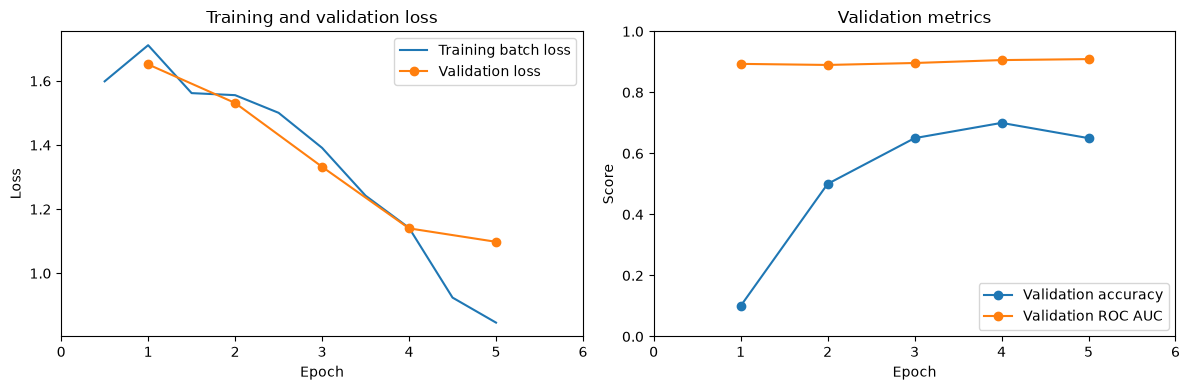

In [12]:
train_history_df = pd.DataFrame(train_history)
val_history_df = pd.DataFrame(val_history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))


axes[0].plot(
    train_history_df["epoch"], train_history_df["loss"], label="Training batch loss"
)
axes[0].plot(
    val_history_df["epoch"], val_history_df["loss"], marker="o", label="Validation loss"
)
axes[0].set(title="Training and validation loss", ylabel="Loss")

axes[1].plot(
    val_history_df["epoch"],
    val_history_df["accuracy"],
    marker="o",
    label="Validation accuracy",
)
axes[1].plot(
    val_history_df["epoch"],
    val_history_df["auc"],
    marker="o",
    label="Validation ROC AUC",
)
axes[1].set(title="Validation metrics", ylabel="Score", ylim=(0, 1))

for axis in axes:
    axis.set_xlabel("Epoch")
    axis.set_xlim([0, max_epoch + 1])
    axis.legend()

plt.tight_layout()
plt.show()

## 3. Evaluate the Selected Checkpoint

Reload `best_metric_model.pth` into a new adapter and run inference on `test_ds`. The predictions DataFrame contains image names, predicted classes, and ground-truth labels. The CSV's label mapping supplies consistent class names for the classification report and confusion matrix.

With `selector="accuracy"` and the same images and preprocessing for validation and test, the reloaded checkpoint's accuracy should match `best_metric`, not necessarily the final entry in `val_history`. Selecting by AUC or loss can choose a different epoch.

Inference: 100%|██████████████████████████████| 20/20 [00:00<00:00, 1490.73it/s]

                  precision    recall  f1-score   support

      No Finding       0.67      0.50      0.57         4
 Support Devices       0.57      0.80      0.67         5
Pleural Effusion       0.83      0.83      0.83         6
    Cardiomegaly       1.00      0.67      0.80         3
     Atelectasis       0.50      0.50      0.50         2

        accuracy                           0.70        20
       macro avg       0.71      0.66      0.67        20
    weighted avg       0.73      0.70      0.70        20



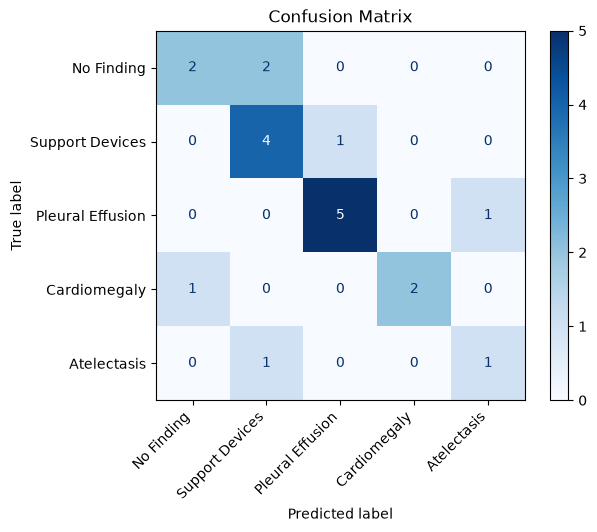

In [16]:
from sklearn.metrics import classification_report

model_path = os.path.join(output_dir, "best_metric_model.pth")
model_inference = AdapterModel(in_channels, hidden_dim, num_class)
model_inference = inference.load_trained_model(model_inference, model_path)
predictions = pd.DataFrame(inference.perform_inference(model_inference, test_ds))

label_category = (
    test_df.drop_duplicates("Label").set_index("Label")["Label Category"].sort_index()
)
report = classification_report(
    predictions["Label"],
    predictions["PredictedClass"],
    labels=label_category.index,
    target_names=label_category.tolist(),
)
print(report)

cm = confusion_matrix(
    predictions["Label"], predictions["PredictedClass"], labels=label_category.index
)
disp = ConfusionMatrixDisplay(cm, display_labels=label_category.tolist())
disp.plot(cmap=plt.cm.Blues)
plt.xticks(rotation=45, ha="right")
plt.title("Confusion Matrix")
plt.show()

### Interpret the Results

The best test accuracy reported during the local experiments was **70% (14 of 20 images)**. This is an observed result, not a guaranteed outcome for the saved settings or either model variant. Use the classification report above for the result of your own run.

Each test image changes accuracy by five percentage points. With this small split, changes to initialization, training settings, or embeddings can noticeably change the result. Because the test split is also used for validation and checkpoint selection here, this score is not an independent estimate of generalization.

Inspect the confusion matrix to identify errors rather than assuming which classes will improve. A larger dataset with a separate validation split is the next step before drawing conclusions about model performance.

## 4. Compare Adapter and Zero-Shot Predictions

Run the [zero-shot notebook](./zero-shot-classification.ipynb) with the same model variant first. This section reads its generated `zero_shot_classification_results.csv` from the shared working directory, rather than using the bundled results from an earlier experiment.

Export the adapter predictions, join the two result tables by image name, and display four fixed examples with their reference labels. The examples make individual agreements and errors visible; they do not replace evaluation on the full test split.

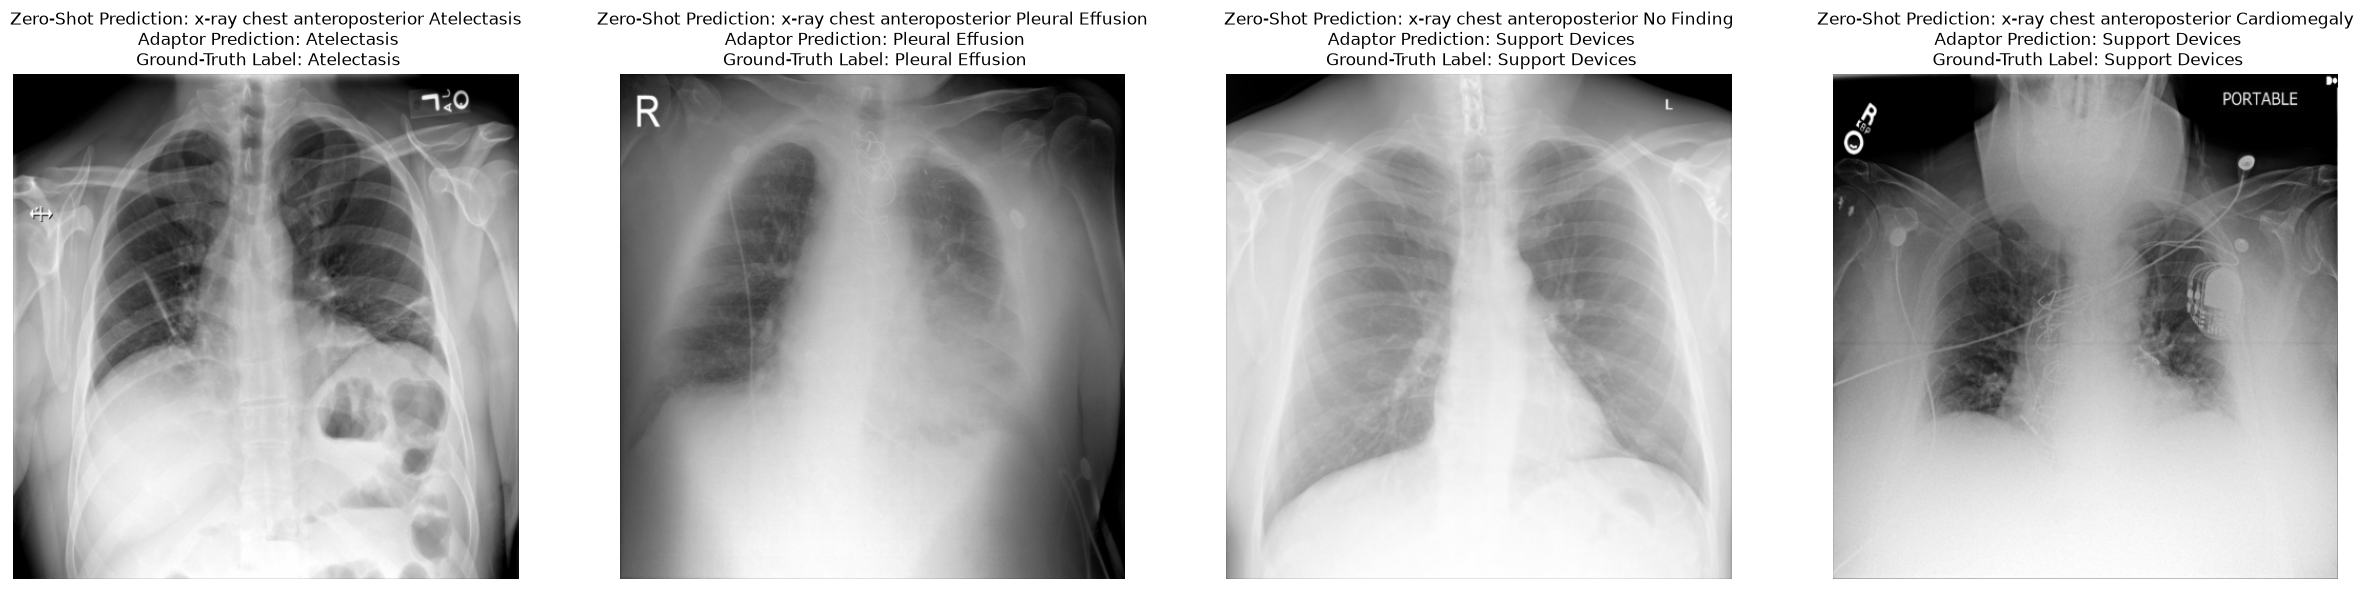

In [ ]:
df = (
    predictions[["Name"]]
    .rename(columns={"Name": "file_name"})
    .assign(
        zero_shot_pred=predictions["PredictedClass"].map(label_category),
        ground_truth_label=predictions["Label"].map(label_category),
    )
)
df.to_csv("./adaptor_finetuning_classification_results.csv", index=False)

df_zero_shot = pd.read_csv("./zero_shot_classification_results.csv")
selected_images = [
    "1.3.6.1.4.1.55648.013051327602219610100989737191708734008.2.1.green.dcm",
    "1.3.6.1.4.1.55648.045678110342520932233807899271374363433.1.1.green.dcm",
    "1.3.6.1.4.1.55648.255611619245397591591431066926543031128.1312.1.green.dcm",
    "1.3.6.1.4.1.55648.023647312006371870964474485493542161185.1.1.green.dcm",
]
selected_data = (
    df.set_index("file_name")
    .join(
        df_zero_shot.set_index("file_name")["zero_shot_pred"].rename(
            "baseline_prediction"
        ),
        validate="one_to_one",
    )
    .loc[selected_images]
)

fig, axs = plt.subplots(1, 4, figsize=(30, 10))
for axis, (image_name, row) in zip(axs, selected_data.iterrows()):
    image_path = os.path.join(input_folder, image_name)
    image = mi2_client.read_and_normalize_image(image_path)
    axis.imshow(image, cmap="bone")
    axis.axis("off")
    axis.set_title(
        "Zero-Shot Prediction: {}\n Adapter Prediction: {}\n Ground-Truth Label: {}".format(
            row["baseline_prediction"], row["zero_shot_pred"], row["ground_truth_label"]
        )
    )

plt.show()

## 5. Next Steps

This notebook trains and evaluates an adapter while keeping the embedding model fixed. To make a stronger comparison, collect more labeled examples, keep a separate test set, and compare zero-shot and adapter predictions on the same images. Record the model variant, training settings, and selected checkpoint with each result.

The [MedImageInsight fine-tuning example](./finetuning/mi2-finetuning.ipynb) explores updating the embedding model itself, which is separate from training this local adapter.